# Used Car Price Prediction with Multiple Linear Regression (OLS)

**Goal:** Build and evaluate a multiple linear regression model that predicts a used car's **price** from its **engine power**, **registration year** and **mileage (kms)**. Then interpret what the model tells us about how car prices work.

**Dataset:** `Span_new.csv`, about 92,000 used-car listings. Prices are in euros.

| Column | Description |
|---|---|
| `Unnamed: 0` | Leftover row index from a previous export (not a feature) |
| `ID` | Listing identifier (not a feature) |
| `make`, `model` | Manufacturer and model name |
| `months_old` | Age of the car in months |
| `power` | Engine power (hp) |
| `gear` | Transmission type |
| `fuel_type` | Fuel type |
| `kms` | Mileage in kilometres |
| `price` | Listing price (target variable) |
| `age` | Registration **year** (renamed to `year` below, since it holds a year, not an age) |

### Contents
1. Setup
2. Load the data
3. Data overview
4. Exploratory data analysis (EDA)
5. Data preprocessing
6. Feature selection
7. Train/test split
8. Model training and interpretation
9. Predictions on the test set
10. Model evaluation
11. Residual diagnostics
12. Predicting the price of a new car
13. Conclusions and next steps

## 1. Setup

Install the libraries once, if they are not already available, by uncommenting the line below.

In [1]:
# %pip install numpy pandas matplotlib seaborn statsmodels scikit-learn

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore", category=FutureWarning)

# Display and plotting settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)

# A fixed seed makes the train/test split, and so every result below, reproducible
RANDOM_STATE = 42

## 2. Load the data

Update `DATA_PATH` to point to the CSV file on your machine.

In [3]:
DATA_PATH = r"C:\Users\bilal\Desktop\gitRepo\Locked\LockedItems\Datasets\Span_new.csv"

df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Dataset loaded: 92,385 rows x 11 columns


,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
0,0,97860,Porsche,911,240,210,manual,gasoline,202000,999999,1998
1,1,27821,Ford,Mustang,54,487,manual,gasoline,30000,685000,2013
2,2,97801,Porsche,911,358,220,manual,gasoline,56300,555555,1988
3,3,98251,Porsche,911,14,368,manual,gasoline,2800,470000,2016
4,4,98250,Porsche,911,3,515,unknown,gasoline,10,450000,2017


In [4]:
df.tail()

,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
92380,93986,38173,Opel,Astra,275,52,manual,gasoline,134700,350,1995
92381,93987,57303,Volkswagen,Polo,232,37,manual,gasoline,67762,350,1998
92382,93988,14541,Bmw,320,186,125,manual,gasoline,200000,300,2002
92383,93989,103604,Seat,Toledo,276,66,manual,gasoline,196000,300,1995
92384,93990,99672,Seat,Cordoba,232,81,manual,diesel,150000,200,1998


## 3. Data overview
### 3.1 Structure and data types

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 92385 entries, 0 to 92384
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  92385 non-null  int64
 1   ID          92385 non-null  int64
 2   make        92385 non-null  str  
 3   model       92385 non-null  str  
 4   months_old  92385 non-null  int64
 5   power       92385 non-null  int64
 6   gear        92385 non-null  str  
 7   fuel_type   92385 non-null  str  
 8   kms         92385 non-null  int64
 9   price       92385 non-null  int64
 10  age         92385 non-null  int64
dtypes: int64(7), str(4)
memory usage: 9.9 MB


> **Interpretation**
> - The dataset has **92,385 listings and 11 columns**: 7 numeric and 4 categorical (`make`, `model`, `gear`, `fuel_type`).
> - `Unnamed: 0` is a leftover index from an earlier export and `ID` is just an identifier. Neither carries information about price, so they must **not** be used as features.
> - The column `age` actually holds the **registration year** (for example 1998 or 2017), so we rename it to `year` during preprocessing to avoid confusion.

### 3.2 Missing values and duplicates

In [6]:
quality = pd.DataFrame({
    "missing_values": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
print(f"Fully duplicated rows: {df.duplicated().sum():,}")
print(f"Duplicated listing IDs: {df['ID'].duplicated().sum():,}")
quality

Fully duplicated rows: 0
Duplicated listing IDs: 0


,missing_values,missing_%,unique_values
Unnamed: 0,0,0.00,92385
ID,0,0.00,92385
make,0,0.00,36
model,0,0.00,247
months_old,0,0.00,366
power,0,0.00,306
gear,0,0.00,4
fuel_type,0,0.00,6
kms,0,0.00,26163
price,0,0.00,4226


> **Interpretation**
> - There are **no missing values** in any column, so no imputation is needed.
> - Check the duplicate counts printed above. Repeated listings would give some cars extra weight in the model, so any duplicates found should be removed before modelling.

### 3.3 Summary statistics: numeric columns

In [8]:
df.describe()

,Unnamed: 0,ID,months_old,power,kms,price,age
count,"92,385.00","92,385.00","92,385.00","92,385.00","92,385.00","92,385.00","92,385.00"
mean,"47,257.59","55,127.58",63.78,99.82,"83,161.96","16,511.69","2,012.24"
std,"27,180.24","33,146.30",56.87,42.75,"75,231.34","15,568.47",4.75
min,0.00,25.00,1.00,0.00,1.00,200.00,"1,987.00"
25%,"23,696.00","25,434.00",17.00,77.00,"18,616.00","8,500.00","2,009.00"
50%,"47,461.00","53,909.00",46.00,88.00,"66,687.00","13,345.00","2,014.00"
75%,"70,849.00","83,611.00",97.00,110.00,"129,000.00","19,990.00","2,016.00"
max,"93,990.00","113,143.00",372.00,809.00,"497,000.00","999,999.00","2,017.00"


> **Interpretation**
> - **Price** has a mean of about **€16,500** but a median of only about **€13,300**. When the mean is well above the median, the distribution is **right-skewed**: a small number of very expensive cars pull the average up.
> - The maximum price of **€999,999** is suspicious. It looks like a placeholder value rather than a real price, and it is a strong **outlier** that a linear model will be sensitive to.
> - **kms** ranges from 1 km (practically new) to about 497,000 km, and **age** (the registration year) ranges from 1987 to 2017. Most cars are fairly recent, with a median year of 2014.

### 3.4 Summary statistics: categorical columns

In [11]:
df.select_dtypes(exclude="number").describe().T

,count,unique,top,freq
make,92385,36,Bmw,10546
model,92385,247,Golf,2433
gear,92385,4,manual,66584
fuel_type,92385,6,diesel,70699


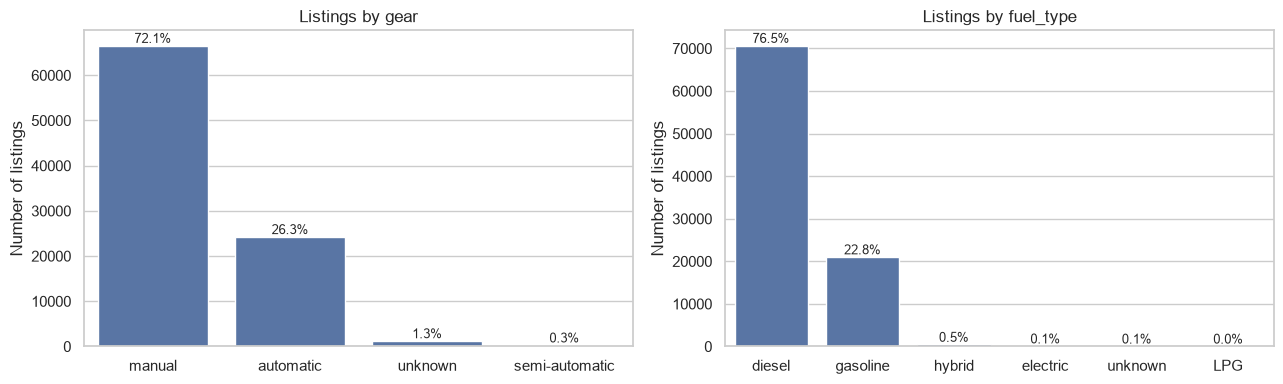

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col in zip(axes, ["gear", "fuel_type"]):
    counts = df[col].value_counts()
    sns.barplot(x=counts.index, y=counts.values, ax=ax)
    ax.set_title(f"Listings by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Number of listings")
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v / len(df):.1%}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

> **Interpretation**
> - **Transmission:** about 72% of cars are manual and about 26% automatic. `unknown` and `semi-automatic` together make up less than 2%.
> - **Fuel:** diesel dominates with about 76% of listings, followed by gasoline at about 23%. Hybrid, electric, LPG and unknown are rare.
> - The data is spread across **36 makes and 247 models**, with BMW the most common make and the VW Golf the most common model.
> - These categorical variables are likely to affect price, but this baseline model uses numeric features only. Encoding them is listed as a next step at the end.

## 4. Exploratory data analysis (EDA)
### 4.1 Distribution of the target variable (price)

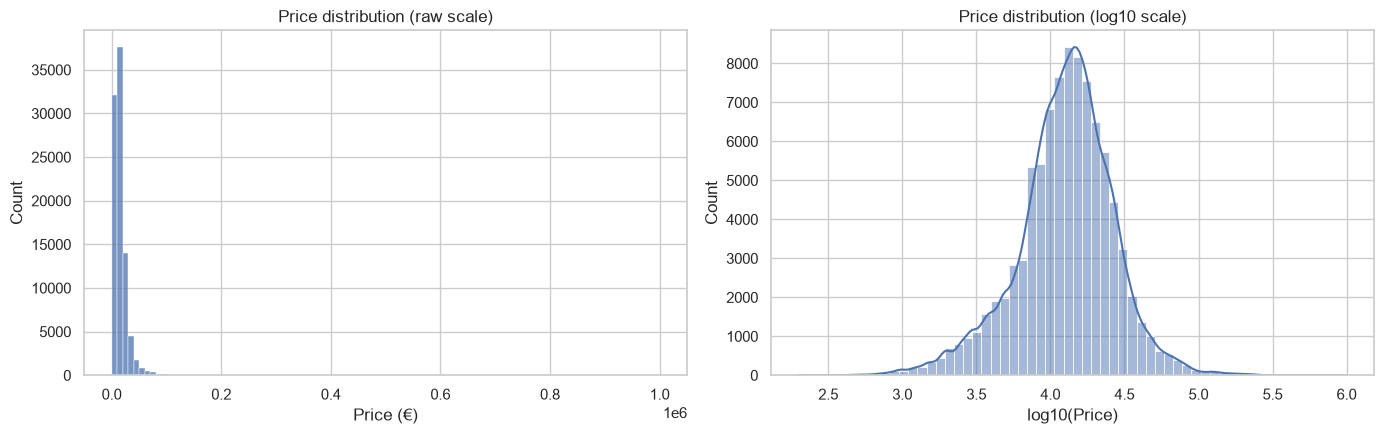

Skewness of price: 9.09


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df["price"], bins=100, ax=axes[0])
axes[0].set_title("Price distribution (raw scale)")
axes[0].set_xlabel("Price (€)")

sns.histplot(np.log10(df["price"]), bins=60, kde=True, ax=axes[1])
axes[1].set_title("Price distribution (log10 scale)")
axes[1].set_xlabel("log10(Price)")

plt.tight_layout()
plt.show()

print(f"Skewness of price: {df['price'].skew():.2f}")

> **Interpretation**
> - On the raw scale, almost all listings are packed into the left part of the chart, with a long tail to the right. Price is **heavily right-skewed**.
> - On the log scale the distribution looks much closer to a bell curve. This suggests that modelling **log(price)** instead of price could fit better, because car values tend to change by *percentages* rather than by fixed euro amounts.
> - A skewness value well above 1 confirms strong right skew.

### 4.2 The most expensive listings

In [14]:
df.sort_values("price", ascending=False).head(10)

,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
0,0,97860,Porsche,911,240,210,manual,gasoline,202000,999999,1998
1,1,27821,Ford,Mustang,54,487,manual,gasoline,30000,685000,2013
2,2,97801,Porsche,911,358,220,manual,gasoline,56300,555555,1988
3,3,98251,Porsche,911,14,368,manual,gasoline,2800,470000,2016
4,4,98250,Porsche,911,3,515,unknown,gasoline,10,450000,2017
5,5,98222,Porsche,911,17,368,manual,gasoline,145,445000,2016
6,6,62404,Bentley,Continental,6,522,automatic,gasoline,3500,399000,2017
7,7,29736,Mercedes-Benz,Cla200,26,115,manual,gasoline,29000,330000,2015
8,8,62403,Bentley,Continental,5,522,automatic,gasoline,1200,302900,2017
9,9,62402,Bentley,Continental,14,522,automatic,gasoline,17900,289700,2016


> **Interpretation**
> - The top of the price range is dominated by luxury cars (Porsche, Bentley, Ford Mustang) and placeholder-looking prices such as €999,999 and €555,555.
> - These few rows sit far away from the rest of the data. Ordinary least squares minimises *squared* errors, so a handful of extreme points like these can noticeably shift the regression line.

### 4.3 Relationship between each feature and price

To keep the charts readable, they use a random sample of 5,000 listings and leave out the top 1% of prices.

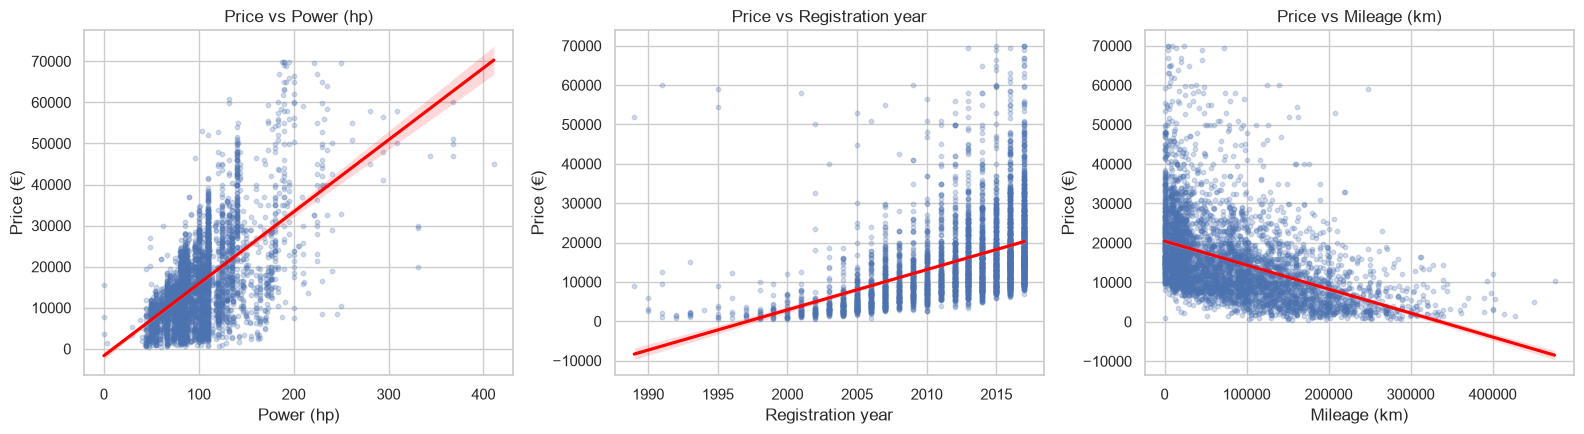

In [15]:
typical = df[df["price"] <= df["price"].quantile(0.99)]
plot_df = typical.sample(n=min(5000, len(typical)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, label in zip(axes, ["power", "age", "kms"],
                          ["Power (hp)", "Registration year", "Mileage (km)"]):
    sns.regplot(data=plot_df, x=col, y="price", ax=ax,
                scatter_kws={"alpha": 0.25, "s": 10}, line_kws={"color": "red"})
    ax.set_title(f"Price vs {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Price (€)")

plt.tight_layout()
plt.show()

> **Interpretation** (what the red trend lines show)
> - **Power vs price:** a clear **positive** relationship. More powerful cars are listed at higher prices.
> - **Year vs price:** a **positive** relationship. Newer cars are worth more because they have lost less value.
> - **Mileage vs price:** a **negative** relationship. Cars with more kilometres sell for less.
> - In all three charts the spread of prices gets wider as prices rise. This uneven spread, called **heteroscedasticity**, shows up again later in the residual diagnostics.

### 4.4 Correlation between numeric variables

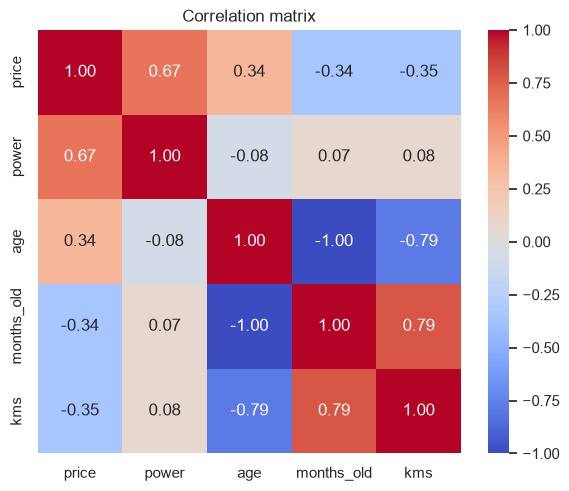

In [16]:
num_cols = ["price", "power", "age", "months_old", "kms"]
corr = df[num_cols].corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix")
plt.show()

> **Interpretation**
> - `power` should show the strongest positive correlation with `price` of the three features. It is the most informative single feature.
> - `age` (year) and `months_old` describe the **same thing**: a car registered earlier is older. Their correlation is close to −1, so including both would cause severe **multicollinearity**, making the coefficients unstable and hard to interpret. We keep only the registration year.
> - `kms` is negatively correlated with price and positively correlated with car age, because older cars have usually been driven more.

## 5. Data preprocessing

Steps:
1. Drop the leftover index column `Unnamed: 0`.
2. Rename `age` to `year`, since it contains the registration year.
3. Remove the five extreme high-price listings at index positions 3 to 7. They were removed in the original analysis, and doing the same keeps the results comparable.

In [17]:
df_clean = (
    df.drop(columns=["Unnamed: 0"])
      .rename(columns={"age": "year"})
      .drop(index=[3, 4, 5, 6, 7])
      .reset_index(drop=True)
)

print(f"Rows before: {len(df):,} | Rows after: {len(df_clean):,} | Removed: {len(df) - len(df_clean)}")
df_clean.head()

Rows before: 92,385 | Rows after: 92,380 | Removed: 5


,ID,make,model,months_old,power,gear,fuel_type,kms,price,year
0,97860,Porsche,911,240,210,manual,gasoline,202000,999999,1998
1,27821,Ford,Mustang,54,487,manual,gasoline,30000,685000,2013
2,97801,Porsche,911,358,220,manual,gasoline,56300,555555,1988
3,62403,Bentley,Continental,5,522,automatic,gasoline,1200,302900,2017
4,62402,Bentley,Continental,14,522,automatic,gasoline,17900,289700,2016


> **Note:** Other extreme prices, such as the €999,999 listing, are **kept on purpose**. This notebook builds a simple **baseline** model, and the diagnostics below show how much these outliers affect it. Handling them more systematically is the first item in the next steps.

## 6. Feature selection

- **Dependent variable (DV, target):** `price`
- **Independent variables (IVs, features):** `power`, `year`, `kms`

Reasons for this choice:
- All three are numeric and showed a clear relationship with price in the EDA.
- `months_old` is left out because it duplicates the information in `year`.
- `ID` is left out because identifiers have no predictive meaning.
- Categorical features (`make`, `model`, `gear`, `fuel_type`) would need encoding first and are left for a later iteration.

In [18]:
FEATURES = ["power", "year", "kms"]
TARGET = "price"

X = df_clean[FEATURES]
y = df_clean[TARGET]

X.head()

,power,year,kms
0,210,1998,202000
1,487,2013,30000
2,220,1988,56300
3,522,2017,1200
4,522,2016,17900


## 7. Train/test split

The data is split **80% for training and 20% for testing**. The model learns only from the training set. The test set stands in for "new, unseen cars", so performance on it shows how well the model **generalises**.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

pd.DataFrame(
    {"rows": [len(X_train), len(X_test)], "features": [X_train.shape[1], X_test.shape[1]]},
    index=["Train", "Test"],
)

,rows,features
Train,73904,3
Test,18476,3


## 8. Model training and interpretation

`statsmodels.OLS` fits a line **through the origin** unless we add an intercept column. `sm.add_constant()` adds that column (named `const`). Without it, the model would be forced to predict a price of 0 when every feature is 0, which usually lowers R² and biases the coefficients.

The fitted model has the form:

$$\widehat{\text{price}} = \beta_0 + \beta_1 \cdot \text{power} + \beta_2 \cdot \text{year} + \beta_3 \cdot \text{kms}$$

In [20]:
X_train_const = sm.add_constant(X_train)
X_test_const = sm.add_constant(X_test)

ols_model = sm.OLS(y_train, X_train_const)
results = ols_model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.622
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                 4.050e+04
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        03:03:05   Log-Likelihood:            -7.8265e+05
No. Observations:               73904   AIC:                         1.565e+06
Df Residuals:                   73900   BIC:                         1.565e+06
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -1.34e+06   2.42e+04    -55.314      0.0

### 8.1 Interpreting the regression summary

*The figures below come from a run on the full dataset. They may differ slightly with a different train/test split.*

**Overall model fit**

| Metric | Value | Meaning |
|---|---|---|
| R-squared | ≈ 0.62 | Power, year and mileage together explain about **62% of the variation** in car prices on the training data. The remaining 38% comes from factors not in the model, such as brand, condition and transmission. |
| Adj. R-squared | ≈ 0.62 | Same as R², adjusted for the number of features. Because it equals R², no feature is just adding noise. |
| F-statistic (p ≈ 0.000) | ≈ 40,000 | The model as a whole is **statistically significant**: the three features jointly explain price far better than simply using the average price. |

**Coefficients** (each effect holds the other features constant)

| Feature | Coefficient | Interpretation |
|---|---|---|
| `const` | ≈ −1,331,000 | The predicted price when power, year and kms are all 0. "Year 0" is not a realistic car, so this number has **no practical meaning**. It only positions the regression line. |
| `power` | ≈ **+252** | Each extra **1 hp** adds about **€252** to the expected price, so +100 hp adds about €25,000. Power has the largest t-value (≈ 308), making it the strongest predictor. |
| `year` | ≈ **+659** | Each year **newer** a car is adds about **€659**. Put the other way, a car loses about €659 in value per year of age. |
| `kms` | ≈ **−0.05** | Each extra km lowers the price by about €0.05, so every **10,000 km** driven reduces the value by about **€500**. |

**Statistical significance:** every p-value (`P>|t|`) is below 0.05 and no 95% confidence interval contains 0. All three features have a **statistically significant** effect on price. The intervals are also very narrow, because the sample is large.

**Diagnostic statistics**

| Statistic | Value | Meaning |
|---|---|---|
| Durbin-Watson | ≈ 2.0 | A value near 2 means the residuals show **no autocorrelation**. ✅ |
| Omnibus / Jarque-Bera (p ≈ 0.000) | very large | The residuals are **not normally distributed**. ⚠️ |
| Skew ≈ 23, Kurtosis ≈ 1,858 | extreme | A normal distribution has a skew of 0 and a kurtosis of 3. These extreme values come from a few huge errors on the extreme-price listings, confirming the **outlier problem** seen in the EDA. ⚠️ |
| Cond. No. ≈ 7.7e+07 | very large | This flags possible multicollinearity. Here it is mainly a **scaling issue**: `year` is around 2,000 and `kms` is in the hundreds of thousands, while `const` is 1. The VIF check below tests whether there is real multicollinearity. |

### 8.2 Coefficient table with practical effects

In [21]:
ci = results.conf_int()
coef_table = pd.DataFrame({
    "coefficient": results.params,
    "std_error": results.bse,
    "t_value": results.tvalues,
    "p_value": results.pvalues,
    "ci_lower_95": ci[0],
    "ci_upper_95": ci[1],
})

# Express each effect in a unit that is easier to picture
effect_units = {"power": (10, "hp"), "year": (1, "year newer"), "kms": (10_000, "km")}
effects = {}
for feature, (step, unit) in effect_units.items():
    change = results.params[feature] * step
    effects[feature] = f"{'+' if change >= 0 else '−'}€{abs(change):,.0f} per {step:,} {unit}"
coef_table["practical_effect"] = pd.Series(effects)
coef_table

,coefficient,std_error,t_value,p_value,ci_lower_95,ci_upper_95,practical_effect
const,"-1,340,487.51","24,234.22",-55.31,0.00,"-1,387,986.48","-1,292,988.53",NaN
power,256.32,0.83,308.94,0.00,254.69,257.94,"+€2,563 per 10 hp"
year,663.75,12.02,55.23,0.00,640.19,687.30,+€664 per 1 year newer
kms,-0.05,0.00,-66.50,0.00,-0.05,-0.05,"−€504 per 10,000 km"


> **Interpretation:** this table restates the summary in everyday terms. For example, about **+€2,500 per 10 hp**, about **+€660 per year newer** and about **−€500 per 10,000 km**. Power has by far the largest practical effect on price.

### 8.3 Multicollinearity check (VIF)

The **Variance Inflation Factor** measures how much a feature can be predicted from the other features. As a rule of thumb, VIF < 5 is fine, 5 to 10 is moderate, and > 10 is a problem. The constant's VIF is ignored.

In [22]:
vif = pd.DataFrame({
    "feature": X_train_const.columns,
    "VIF": [variance_inflation_factor(X_train_const.values, i) for i in range(X_train_const.shape[1])],
}).query("feature != 'const'")
vif

,feature,VIF
1,power,1.01
2,year,2.61
3,kms,2.61


> **Interpretation:** if every VIF is well below 5, the three features are not strongly related to one another. That would mean the large condition number reported above comes from the different **scales** of the variables rather than from real multicollinearity, so the coefficients can be trusted. (Had we also included `months_old`, its VIF and that of `year` would be extremely high.)

## 9. Predictions on the test set

In [23]:
y_pred = results.predict(X_test_const)

comparison = pd.DataFrame({
    "actual_price": y_test,
    "predicted_price": y_pred,
})
comparison["error"] = comparison["actual_price"] - comparison["predicted_price"]
comparison["abs_error"] = comparison["error"].abs()
comparison["abs_pct_error"] = comparison["abs_error"] / comparison["actual_price"] * 100

comparison.head(10)

,actual_price,predicted_price,error,abs_error,abs_pct_error
53928,11600,"20,473.16","-8,873.16","8,873.16",76.49
39092,14950,"11,899.62","3,050.38","3,050.38",20.40
12687,26300,"22,032.92","4,267.08","4,267.08",16.22
42483,14000,"22,758.01","-8,758.01","8,758.01",62.56
17022,23321,"24,684.15","-1,363.15","1,363.15",5.85
6667,33400,"26,282.25","7,117.75","7,117.75",21.31
12351,26600,"23,712.99","2,887.01","2,887.01",10.85
31464,16990,"15,467.66","1,522.34","1,522.34",8.96
42654,14000,"20,365.92","-6,365.92","6,365.92",45.47
71267,7990,"11,719.26","-3,729.26","3,729.26",46.67


> **Interpretation**
> - `error` = actual − predicted. A positive value means the model **under-priced** the car, and a negative value means it **over-priced** it.
> - Comparing actual and predicted prices for an *exact* match, as the earlier version of this notebook did, is not useful for regression. Predictions are continuous numbers and almost never equal the actual price to the cent, so that check would always return `False`. It is better to measure **how far** each prediction is from the actual price, as done here.

In [24]:
n_negative = (y_pred < 0).sum()
print(f"Negative price predictions: {n_negative:,} of {len(y_pred):,} ({n_negative / len(y_pred):.2%})")

Negative price predictions: 1,011 of 18,476 (5.47%)


> **Interpretation:** a linear model has no built-in lower limit, so it can predict **negative prices** for old, low-power, high-mileage cars. Any negative predictions counted above are a sign that a straight line does not fully capture how cars lose value. Modelling `log(price)` would avoid this problem.

## 10. Model evaluation

The same metrics are computed on the **training** and **test** sets so that we can check for overfitting.

In [25]:
def regression_metrics(y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    return {
        "R²": r2_score(y_true, y_hat),
        "MAE (€)": mean_absolute_error(y_true, y_hat),
        "RMSE (€)": np.sqrt(mse),
        "Median abs. % error": np.median(np.abs((y_true - y_hat) / y_true)) * 100,
    }

y_train_pred = results.predict(X_train_const)

metrics = pd.DataFrame({
    "Train": regression_metrics(y_train, y_train_pred),
    "Test": regression_metrics(y_test, y_pred),
})
metrics

,Train,Test
R²,0.62,0.69
MAE (€),"4,760.44","4,634.02"
RMSE (€),"9,615.83","7,707.05"
Median abs. % error,22.92,22.82


### Interpreting the metrics

*Reference values from a run on the full dataset: test R² ≈ 0.68, MAE ≈ €4,700, RMSE ≈ €8,450.*

| Metric | Meaning | Reading |
|---|---|---|
| **R²** | Share of the variation in price that the model explains | About 0.68 on the test set: the model captures roughly **two-thirds** of what drives price. That is a reasonable baseline for only 3 features. |
| **MAE** | Average absolute prediction error in euros | Predictions are off by about **€4,700** on average. Given an average price of about €16,500, that is roughly 28%, which is useful for rough estimates but not precise enough for pricing decisions. |
| **RMSE** | Like MAE, but large errors are penalised more | RMSE (about €8,450) is nearly **twice the MAE**, which means a small number of **very large errors** (luxury and outlier cars) push the error up. |
| **Median abs. % error** | Typical percentage error for a single car | Not affected by extreme prices, so it describes a "typical" car better than MAE or RMSE do. |

**Overfitting check:** train and test results are close, so the model is **not overfitting**. With 3 features and about 74,000 training rows, this is expected. If test R² comes out *higher* than train R², it is not a red flag. It usually means the most extreme listings, such as the €999,999 car, landed in the training set, where they make R² worse.

## 11. Residual diagnostics

Linear regression assumes that the residuals (errors) are **centred on zero**, have **constant variance** and are **roughly normally distributed**. The charts below check each of these.

### 11.1 Actual vs predicted prices

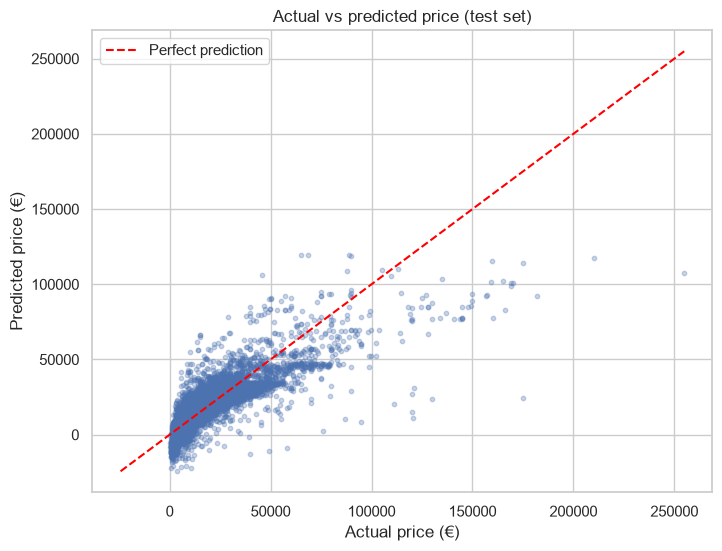

In [26]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_pred, alpha=0.3, s=10)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax.plot(lims, lims, color="red", linestyle="--", label="Perfect prediction")
ax.set_xlabel("Actual price (€)")
ax.set_ylabel("Predicted price (€)")
ax.set_title("Actual vs predicted price (test set)")
ax.legend()
plt.show()

> **Interpretation:** points on the red dashed line are perfect predictions. Points **above** the line are over-priced by the model and points **below** are under-priced. Expect a dense cloud near the line for typical cars (under about €30,000) and points falling well **below** the line for expensive cars. A linear model with only 3 features cannot capture the premium of luxury brands, so it **systematically under-prices high-end cars**.

### 11.2 Residuals vs predicted values

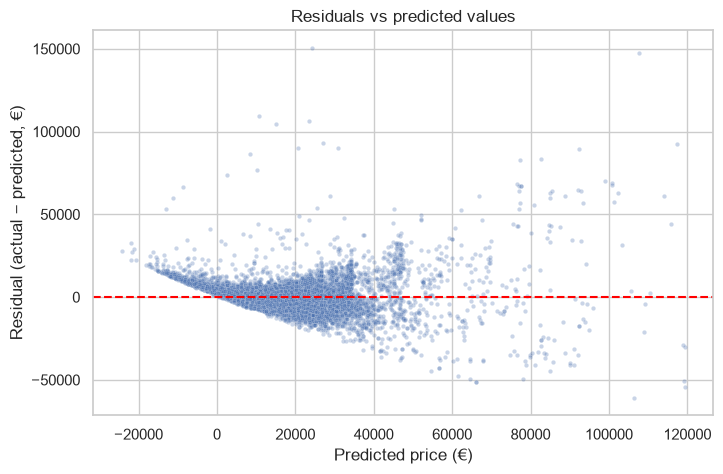

In [27]:
residuals = y_test - y_pred

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.3, s=10, ax=ax)
ax.axhline(0, color="red", linestyle="--")
ax.set_xlabel("Predicted price (€)")
ax.set_ylabel("Residual (actual − predicted, €)")
ax.set_title("Residuals vs predicted values")
plt.show()

> **Interpretation**
> - **Ideal pattern:** a random, even band of points around the zero line.
> - **What to watch for here:** a **funnel shape**, where residuals spread out as predicted prices rise. That is **heteroscedasticity**: the model's errors are larger for expensive cars. It does not bias the coefficients, but it makes the standard errors and p-values less reliable.
> - A curved pattern would indicate a **non-linear** relationship, such as cars losing value faster in their first years. Modelling `log(price)` usually helps with both problems.

### 11.3 Distribution of residuals

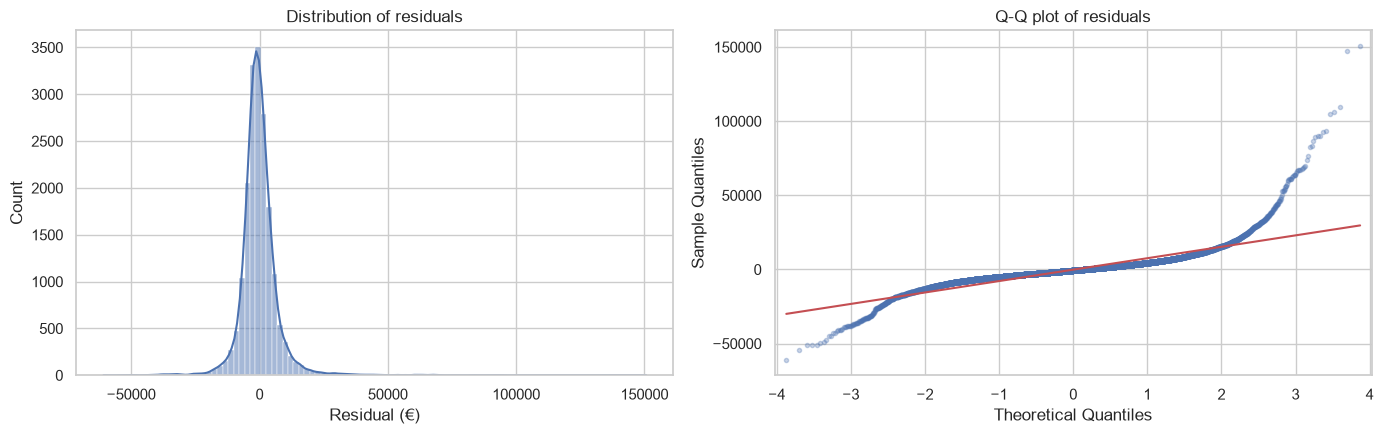

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(residuals, bins=100, kde=True, ax=axes[0])
axes[0].set_title("Distribution of residuals")
axes[0].set_xlabel("Residual (€)")

sm.qqplot(residuals, line="s", ax=axes[1], alpha=0.3, markersize=3)
axes[1].set_title("Q-Q plot of residuals")

plt.tight_layout()
plt.show()

> **Interpretation**
> - **Histogram:** most residuals are concentrated around zero, which is good, but there are **long tails**, especially on the positive side. These are expensive cars that the model under-predicts.
> - **Q-Q plot:** if residuals were normal, the points would follow the red line. Points bending away at both ends ("heavy tails") confirm what the Omnibus and Jarque-Bera tests reported: **the residuals are not normal**.
> - **Impact:** with this many observations, the coefficients are still sound estimates. However, the p-values and confidence intervals should be read with some caution.

## 12. Predicting the price of a new car

To predict a single car, pass a DataFrame with **the same column names and order** used in training, plus the constant.

In [29]:
new_car = pd.DataFrame({
    "power": [150],     # hp
    "year": [2015],     # registration year
    "kms": [60_000],    # mileage
})

new_car_const = sm.add_constant(new_car, has_constant="add")
predicted_price = results.predict(new_car_const)[0]

print(f"Estimated price for a 150 hp, 2015 car with 60,000 km: €{predicted_price:,.0f}")

Estimated price for a 150 hp, 2015 car with 60,000 km: €32,384


> **Interpretation:** the model combines the effects estimated above. It starts from the intercept, adds about €252 per hp and about €659 per registration year, and subtracts about €0.05 per km. Since the typical error (MAE) is about €4,700, this estimate should be read as a **ballpark figure**, not an exact price.

## 13. Conclusions and next steps

### Key findings
1. **Power, year and mileage are all significant drivers of price** (p < 0.001):
   - +10 hp → about **+€2,500**
   - +1 year newer → about **+€660**
   - +10,000 km → about **−€500**
2. With just these three features, the model explains about **62% to 68% of price variation**, with a typical error of about **€4,700**.
3. The model **generalises well** (train and test scores are similar), so it is not overfitting.
4. The main weaknesses are **extreme-price outliers**, **non-normal residuals** with **unequal variance**, and some **negative price predictions**. Each of these suggests that a straight-line model of raw price is too simple for this data.

### Recommended next steps
| Step | Expected benefit |
|---|---|
| Remove or cap extreme and placeholder prices (for example €999,999) using IQR or percentile rules | Cleaner fit, more reliable coefficients |
| Model **log(price)** instead of price | Handles skew and heteroscedasticity, prevents negative predictions, and lets coefficients be read as % effects |
| Add categorical features (`make`, `gear`, `fuel_type`) with one-hot encoding | Captures the brand premium, which is likely the biggest missing factor |
| Centre or standardise numeric features | Removes the large condition number and makes the intercept meaningful |
| Use k-fold cross-validation | More reliable performance estimate than a single split |
| Compare with non-linear models (Random Forest, Gradient Boosting) | Captures non-linear depreciation and interactions between features |